# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**AI-use disclosure for this combined working copy:** Questions 1–3 are preserved from the linked GitHub notebook. Questions 4–6 were added with AI assistance. Therefore, this combined notebook should **not** be represented as a Phase 1 solution completed without generative AI. Follow the course rules for Phase 1 versus Phase 2 when submitting.

**Student(s):** Charlotte Olexy, Maya Yonathan, Mouad Tazka

**Date of original notebook:** 11/17/2026

In [1]:
# Your Phase 1 solution to the problem goes here.

import pandas as pd
import numpy as np

heart = pd.read_csv("../../../../Downloads/heart_failure_clinical_records_dataset.csv")

heart.head(5)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [2]:
#drop any na values and clean the Age variable 
heart.dropna()

heart["age"] = np.floor(heart["age"])

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression

heart_no_target = heart.drop(columns = "DEATH_EVENT")

X = heart_no_target
y = heart["DEATH_EVENT"]

seeds = [42, 101, 123, 456]
results = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    tree = DecisionTreeClassifier(random_state=seed)
    tree.fit(X_train, y_train)

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    tree_predictions = tree.predict(X_test)
    linear_predictions = linear_model.predict(X_test)

    results.append({
        "seed": seed,
        "tree": tree,
        "linear model": linear_model,
        "tree prediction": tree_predictions,
        "linear prediction": linear_predictions
        })

print(results)

[{'seed': 42, 'tree': DecisionTreeClassifier(random_state=42), 'linear model': LinearRegression(), 'tree prediction': array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1]), 'linear prediction': array([ 1.59253109e-01, -1.49250611e-01,  2.60210853e-01,  1.57809193e+00,
        2.70519005e-01,  9.22297065e-03,  5.30345820e-01,  2.77933803e-01,
        8.35339211e-01,  2.23000344e-01,  2.82241720e-01,  1.52357167e-01,
        2.34135496e-01,  3.34484236e-01,  3.59330278e-01,  5.40661659e-01,
        1.07127451e-01,  4.01724635e-01,  2.80515761e-01,  4.30053077e-01,
        4.40099556e-01,  3.83372551e-01,  2.89713414e-01,  5.42986664e-01,
        5.23186311e-01, -1.51500740e-01,  2.26604631e-02,  1.67466695e-01,
        2.30814616e-01, -8.89392946e-02,  6.90394231e-01, -7.91429395e-02,
        6.12200149e-01,  8.77736795e-01,  5.67119757e-01, 

The decision tree produces categorical outcomes with predictions that change substantially across the different seeds. This shows that changing the training sample can change how the tree classifies observations.

The linear model produce continuous predictions that also change across seeds.

## Q4 — Scatterplots, correlations, and regression

In [4]:
import matplotlib.pyplot as plt

reference_seed = results[0]["seed"]
_, X_reference_test, _, y_reference_test = train_test_split(
    X, y, test_size=0.20, random_state=reference_seed
)

baseline_tree = results[0]["tree"].predict(X_reference_test)
baseline_linear = results[0]["linear model"].predict(X_reference_test)

comparison_rows = []
for item in results[1:]:
    for model_label, model_key, baseline in [
        ("Decision tree", "tree", baseline_tree),
        ("Linear model", "linear model", baseline_linear),
    ]:
        alternate = item[model_key].predict(X_reference_test)
        correlation = np.corrcoef(baseline, alternate)[0, 1]

        # Regress alternative predictions (y) on baseline predictions (x).
        regression = LinearRegression().fit(baseline.reshape(-1, 1), alternate)
        comparison_rows.append({
            "Seed": item["seed"],
            "Model": model_label,
            "Correlation": correlation,
            "Intercept": regression.intercept_,
            "Slope": regression.coef_[0],
            "R2": regression.score(baseline.reshape(-1, 1), alternate),
            "Same tree prediction (%)": (100 * np.mean(baseline == alternate)
                                        if model_label == "Decision tree" else np.nan),
        })

comparison = pd.DataFrame(comparison_rows)
print("All models compared on", len(X_reference_test), "rows from seed", reference_seed)
display(comparison.round(3))

All models compared on 60 rows from seed 42


,Seed,Model,Correlation,Intercept,Slope,R2,Same tree prediction (%)
0,101,Decision tree,0.248,0.366,0.266,0.062,63.333
1,101,Linear model,0.983,0.042,0.970,0.967,NaN
2,123,Decision tree,0.249,0.317,0.262,0.062,65.000
3,123,Linear model,0.980,0.025,0.909,0.961,NaN
4,456,Decision tree,0.297,0.317,0.315,0.088,66.667
5,456,Linear model,0.985,0.041,0.946,0.969,NaN


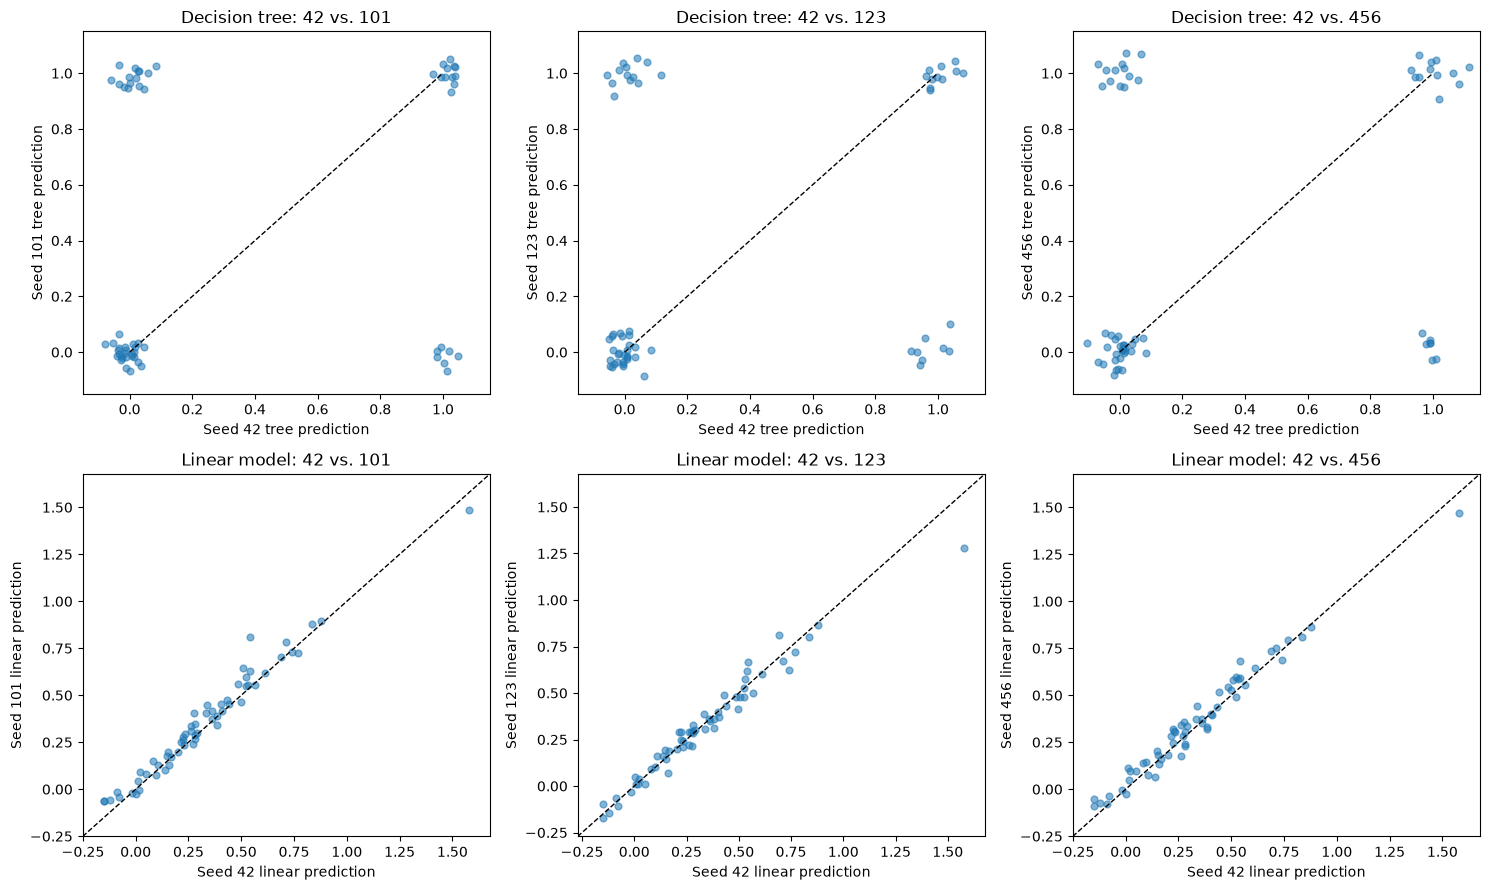

In [5]:
# Q4a: Scatterplots — baseline seed 42 on x-axis, other seeds on y-axis.
fig, axes = plt.subplots(2, len(results) - 1, figsize=(15, 9))
rng = np.random.default_rng(42)

for j, item in enumerate(results[1:]):
    tree_alt = item["tree"].predict(X_reference_test)
    linear_alt = item["linear model"].predict(X_reference_test)
    axes[0, j].scatter(
        baseline_tree + rng.normal(0, 0.04, len(baseline_tree)),
        tree_alt + rng.normal(0, 0.04, len(tree_alt)),
        alpha=0.55, s=24
    )
    axes[0, j].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[0, j].set(xlim=(-0.15, 1.15), ylim=(-0.15, 1.15),
                   xlabel="Seed 42 tree prediction",
                   ylabel=f"Seed {item['seed']} tree prediction",
                   title=f"Decision tree: 42 vs. {item['seed']}")

    axes[1, j].scatter(baseline_linear, linear_alt, alpha=0.55, s=24)
    limits = [min(baseline_linear.min(), linear_alt.min()) - 0.1,
              max(baseline_linear.max(), linear_alt.max()) + 0.1]
    axes[1, j].plot(limits, limits, "k--", linewidth=1)
    axes[1, j].set(xlim=limits, ylim=limits,
                   xlabel="Seed 42 linear prediction",
                   ylabel=f"Seed {item['seed']} linear prediction",
                   title=f"Linear model: 42 vs. {item['seed']}")

plt.tight_layout()
plt.savefig("trees_model_stability_Q4_scatterplots.png", dpi=170, bbox_inches="tight")
plt.show()


### Q4b and Q4c — Interpretation

When I compared the models on the same 60 observations, the **tree predictions were not highly correlated** across seeds: their correlations with the seed-42 predictions ranged from about **0.248 to 0.297**. They agreed on only about **63%–67%** of the classifications. The regression intercepts were around **0.32–0.37**, slopes were around **0.26–0.31**, and R² values were only **0.062–0.088**. Those values are not especially close to the ideal intercept of 0, slope of 1, and R² of 1.

The **linear predictions were much more consistent**. Their correlations were around **0.980–0.985**, with intercepts around **0.025–0.042**, slopes around **0.909–0.970**, and R² values around **0.961–0.969**. The linear scatterplots cluster close to the 45-degree line, while the tree plots show more disagreement.

## Q5 — Coefficients and tree structures

In [6]:
# Q5: Compare linear coefficients and decision-tree structures across seeds.
coefficient_table = pd.DataFrame(
    {f"Seed {item['seed']}": item["linear model"].coef_
     for item in results},
    index=X.columns
)
print("Linear model coefficients (feature units vary):")
display(coefficient_table.round(6))

structure = pd.DataFrame([
    {
        "Seed": item["seed"],
        "Depth": item["tree"].get_depth(),
        "Leaves": item["tree"].get_n_leaves(),
        "Root split feature": X.columns[item["tree"].tree_.feature[0]],
    }
    for item in results
])
print("Decision tree structures:")
display(structure)

Linear model coefficients (feature units vary):


,Seed 42,Seed 101,Seed 123,Seed 456
age,0.006293,0.007078,0.005747,0.005876
anaemia,-0.014492,0.002584,-0.013821,0.023301
creatinine_phosphokinase,0.000017,0.000043,0.000019,0.000025
diabetes,0.037456,0.010693,0.001406,0.052361
ejection_fraction,-0.009022,-0.010645,-0.009289,-0.011409
high_blood_pressure,-0.021997,0.012430,-0.000320,-0.010240
platelets,-0.000000,0.000000,-0.000000,0.000000
serum_creatinine,0.107125,0.082581,0.069897,0.090975
serum_sodium,-0.005685,-0.003069,-0.008791,-0.005918
sex,-0.087143,-0.074927,-0.049542,-0.055527


Decision tree structures:


,Seed,Depth,Leaves,Root split feature
0,42,9,31,time
1,101,11,38,time
2,123,8,35,time
3,456,11,43,time


### Q5 — Interpretation

The linear models have fairly similar overall predictions and several important coefficients keep the same sign across seeds. For example, `age` and `serum_creatinine` stay positive, while `ejection_fraction` and `time` stay negative. Some smaller coefficients, including `anaemia`, `high_blood_pressure`, and `smoking`, do change signs, so the coefficients are **not identical or completely stable**. Overall, though, the linear model predictions are very similar.

The trees change more. Their depths range from **8 to 11**, and their leaf counts range from **31 to 43**. All four trees split first on `time`, but their later branches and classifications differ. Between one-third and slightly more than one-third of the reference observations receive a different classification from the alternative trees compared with seed 42. This supports the idea that an unrestricted decision tree is sensitive to changes in the training data.


## Q6 — Conclusion

### Q6 — True or false?

**For this dataset and these models, I would say false overall.** The trees can look different across the training splits, and in this case their predictions also change by a noticeable amount. The tree prediction correlations with the baseline are only around **0.25–0.30**, and about **33%–37%** of their classifications disagree with the baseline. In contrast, the linear models have very similar predictions, with correlations above **0.98**, even though some individual coefficients change. So the statement may be true in other situations, but it is not well supported for the trees in this experiment. The results show why it is important to check predictions directly instead of judging stability only from what a model looks like.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]